# 03 - Minh chứng Embedded và hệ thống tích hợp

Notebook phục vụ Q17-Q58 và Q70-Q80: trigger, Quality Gate, threshold, TFLM, parity, packet bảo mật, Gateway, MQTT và các giới hạn khi mất kết nối.

In [1]:
from pathlib import Path
from html import escape
import json
import pandas as pd
from IPython.display import display, Image, Markdown, HTML

def find_repo_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'Defense_Package').is_dir():
            return path
    raise FileNotFoundError('Không tìm thấy repository root')

ROOT = find_repo_root()
EVIDENCE = ROOT / 'Defense_Package' / '02_Defense_Evidence'

def show_image(relative_path, width=1100):
    path = EVIDENCE / relative_path
    if not path.exists(): raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))

def show_log(relative_path, lines=80):
    path = EVIDENCE / relative_path
    text = path.read_text(encoding='utf-8', errors='replace').splitlines()
    payload = escape('\n'.join(text[-lines:]))
    display(HTML(
        '<pre style="margin:8px 0;padding:14px 16px;'
        'background:#f8fafc;color:#172033;border:1px solid #cbd5e1;'
        'border-radius:8px;white-space:pre-wrap;overflow-x:auto;'
        'font:13px/1.45 Consolas,Monaco,monospace;">'
        f'{payload}</pre>'
    ))

print('ROOT =', ROOT)

ROOT = d:\NCKH_2026\NCKH_2026_AIOT


## 1. VAD, Quality Gate và threshold là ba quyết định khác nhau - Q23, Q70-Q72

1. **VAD**: khi nào kích hoạt cửa sổ.
2. **Quality Gate**: cửa sổ đã thu có đủ điều kiện suy luận không.
3. **Classification threshold**: score của model được đổi thành lớp như thế nào.

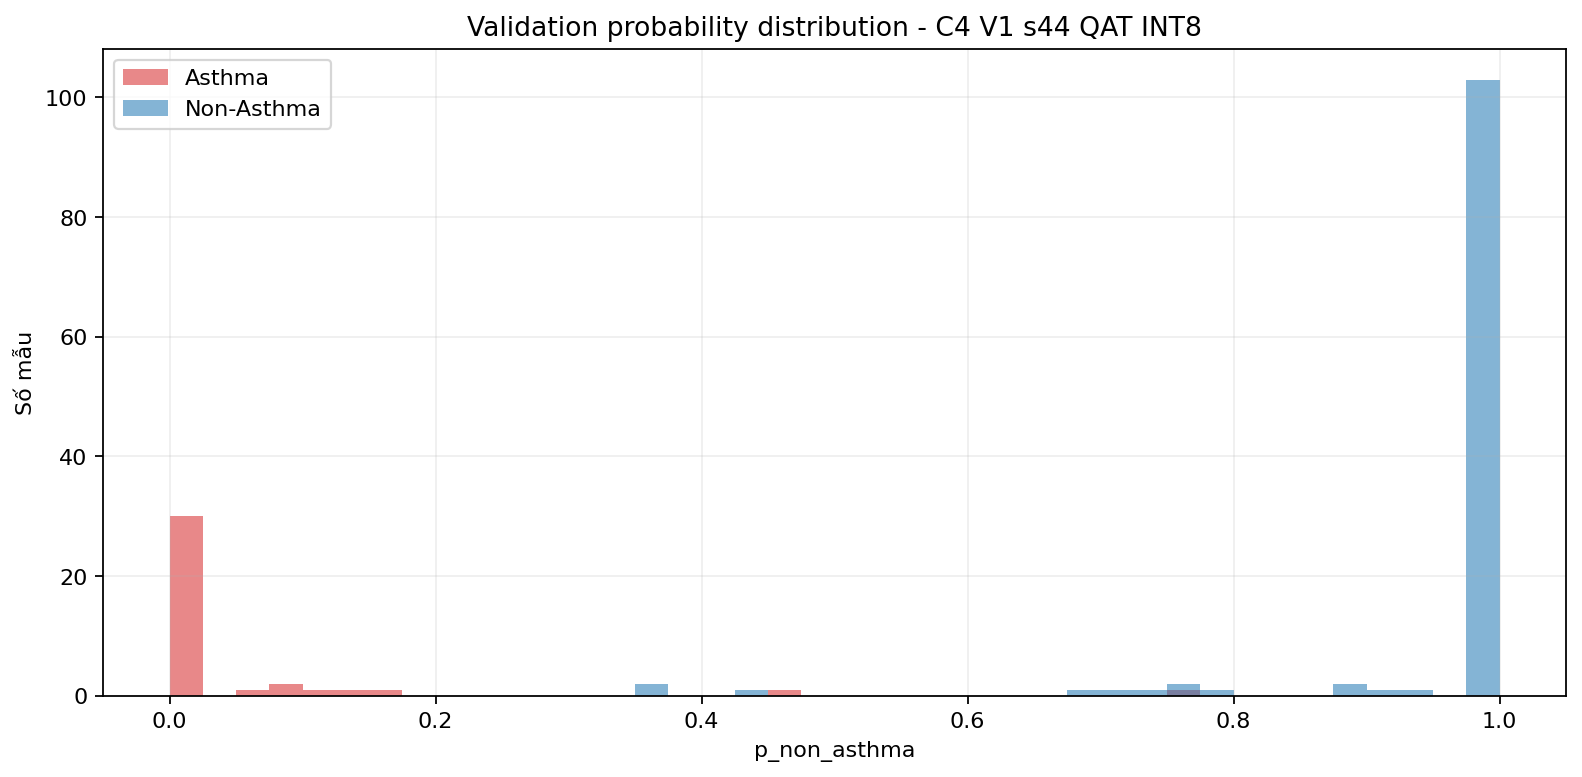

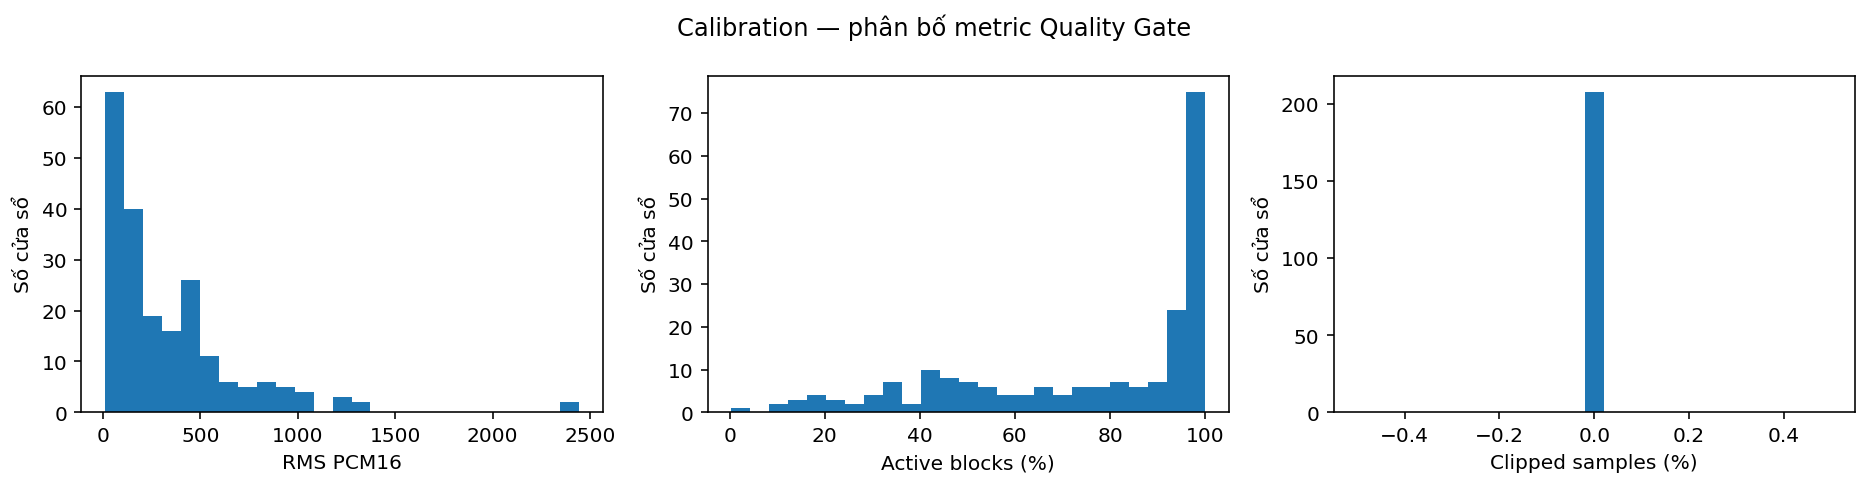


 Classification_Threshold_Final_Metrics.csv


,low_threshold,high_threshold,total,asthma_total,non_asthma_total,asthma_to_asthma,asthma_to_unsure,asthma_to_non_asthma,non_asthma_to_asthma,non_asthma_to_unsure,...,asthma_f1,asthma_miss_rate,asthma_unsure_rate,non_asthma_false_alarm_rate,non_asthma_unsure_rate,overall_unsure_rate,coverage,accepted_accuracy,strict_accuracy,decision_pattern_sha256
0,0.47,0.77,159,38,121,35,0,3,3,6,...,0.921053,0.078947,0.0,0.024793,0.049587,0.037736,0.962264,0.960784,0.924528,21c089ef7e9007cfc9979aaa5341faa12e7cfdaed69dc5...



 Quality_Gate_Test_Metrics.csv


,qc_split,original_split,session_id,subtype,source_kind,file_path,file_name,window_index,crop_start_s,window_seconds,...,clipped_samples,clipped_ratio,active_blocks,total_blocks,active_ratio,dc_offset,rms_dbfs,baseline_state,block_mav_json,final_state
0,test,test,knock_session_02,knock,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,knock_session_02.wav,1,9.9,5,...,0,0.0,78,313,0.249201,-0.546687,-49.648489,AUDIO_OK,"[19,19,9,326,307,222,130,105,48,40,52,31,43,28...",AUDIO_OK
1,test,test,knock_session_02,knock,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,knock_session_02.wav,2,41.8,5,...,0,0.0,97,313,0.309904,-0.427275,-50.183728,AUDIO_OK,"[5,381,246,248,87,96,39,40,47,29,35,21,9,31,6,...",AUDIO_OK
2,test,test,room_noise_session_06,room_noise,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,room_noise_session_06.wav,1,9.9,5,...,0,0.0,0,313,0.000000,-0.509375,-66.918480,AUDIO_INACTIVE,"[11,11,11,13,13,13,11,12,11,11,13,11,12,11,12,...",AUDIO_INACTIVE
3,test,test,room_noise_session_06,room_noise,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,room_noise_session_06.wav,2,41.8,5,...,0,0.0,182,313,0.581470,-0.532162,-57.453782,AUDIO_OK,"[18,15,19,41,47,53,77,84,77,49,35,48,44,72,42,...",AUDIO_OK
4,test,test,speech_session_03,speech,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,speech_session_03.wav,1,9.9,5,...,0,0.0,225,313,0.718850,-0.473587,-45.041011,AUDIO_OK,"[143,139,134,86,40,34,34,33,32,27,50,172,142,7...",AUDIO_OK
5,test,test,speech_session_03,speech,environment_master,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,speech_session_03.wav,2,41.8,5,...,0,0.0,228,313,0.728435,-0.478450,-48.325314,AUDIO_OK,"[17,24,23,16,18,11,12,8,8,62,188,281,244,252,2...",AUDIO_OK
6,test,test,PB_Asthma_AST_037__P11WheezingRS_52,playback_asthma,playback,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,AST_037__P11WheezingRS_52__take01.wav,1,1.0,5,...,0,0.0,85,313,0.271565,-0.497600,-47.505562,AUDIO_OK,"[1,1,1,11,5,2,11,44,53,38,42,29,111,145,52,68,...",AUDIO_OK
7,test,test,PB_Asthma_AST_037__P11WheezingRS_52,playback_asthma,playback,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,AST_037__P11WheezingRS_52__take02.wav,1,1.0,5,...,0,0.0,83,313,0.265176,-0.500812,-47.518235,AUDIO_OK,"[1,1,1,1,1,2,13,2,2,4,17,28,27,111,145,50,68,6...",AUDIO_OK
8,test,test,PB_Asthma_AST_038__P17WheezingIE_85,playback_asthma,playback,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,AST_038__P17WheezingIE_85__take01.wav,1,1.0,5,...,0,0.0,309,313,0.987220,-0.270000,-27.322099,AUDIO_OK,"[1,6,9,2,23,84,318,631,488,307,164,265,584,334...",AUDIO_OK
9,test,test,PB_Asthma_AST_038__P17WheezingIE_85,playback_asthma,playback,D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\...,AST_038__P17WheezingIE_85__take02.wav,1,1.0,5,...,0,0.0,304,313,0.971246,-0.517775,-27.343246,AUDIO_OK,"[1,1,1,1,1,6,12,3,3,49,134,154,294,610,569,150...",AUDIO_OK



 VAD_Test_Trigger_Events.csv


,source_group,file_name,subtype,source_kind,event_no,candidate_onset_s,confirmed_s,confirmation_delay_ms,recovered_samples,recovered_ms,confirm_mav,capture_complete,capture_end_s
0,PB_Asthma_AST_037__P11WheezingRS_52,AST_037__P11WheezingRS_52__take01.wav,playback_asthma,playback,1,1.264,1.328,64.0,1024,64.0,97,True,6.264
1,PB_Asthma_AST_037__P11WheezingRS_52,AST_037__P11WheezingRS_52__take02.wav,playback_asthma,playback,1,1.280,1.344,64.0,1024,64.0,98,True,6.280
2,PB_Asthma_AST_038__P17WheezingIE_85,AST_038__P17WheezingIE_85__take01.wav,playback_asthma,playback,1,1.088,1.152,64.0,1024,64.0,350,True,6.088
3,PB_Asthma_AST_038__P17WheezingIE_85,AST_038__P17WheezingIE_85__take02.wav,playback_asthma,playback,1,1.152,1.216,64.0,1024,64.0,499,True,6.152
4,PB_Asthma_AST_039__P24WheezingRS_120,AST_039__P24WheezingRS_120__take01.wav,playback_asthma,playback,1,1.264,1.328,64.0,1024,64.0,89,True,6.264
5,PB_Asthma_AST_039__P24WheezingRS_120,AST_039__P24WheezingRS_120__take02.wav,playback_asthma,playback,1,1.232,1.296,64.0,1024,64.0,228,True,6.232
6,PB_Asthma_AST_040__P26WheezingIU_126,AST_040__P26WheezingIU_126__take01.wav,playback_asthma,playback,1,1.104,1.168,64.0,1024,64.0,2240,True,6.104
7,PB_Asthma_AST_040__P26WheezingIU_126,AST_040__P26WheezingIU_126__take02.wav,playback_asthma,playback,1,1.120,1.184,64.0,1024,64.0,2704,True,6.120
8,PB_Non_Asthma_Disease_BRO_010__P12BronchialSc_58,BRO_010__P12BronchialSc_58__take01.wav,playback_non_asthma_disease,playback,1,3.264,3.328,64.0,1024,64.0,90,False,NaN
9,PB_Non_Asthma_Disease_BRO_010__P12BronchialSc_58,BRO_010__P12BronchialSc_58__take02.wav,playback_non_asthma_disease,playback,1,3.264,3.328,64.0,1024,64.0,81,False,NaN


In [2]:
show_image('figures/04_Final_Validation/01_Threshold_Probability_Distribution.png')
show_image('figures/04_Final_Validation/02_Quality_Distributions.png')
for name in ['Classification_Threshold_Final_Metrics.csv', 'Quality_Gate_Test_Metrics.csv', 'VAD_Test_Trigger_Events.csv']:
    print('\n', name)
    display(pd.read_csv(EVIDENCE / 'data' / name).head(20))

## 2. Vì sao suy luận tại Node? - Q21, Q25, Q73, Q80

Edge inference giữ âm thanh cục bộ và vẫn hoạt động khi Gateway/Internet mất. Đổi lại phải chứng minh model vừa bộ nhớ, latency chấp nhận được và pipeline C++ khớp Python.

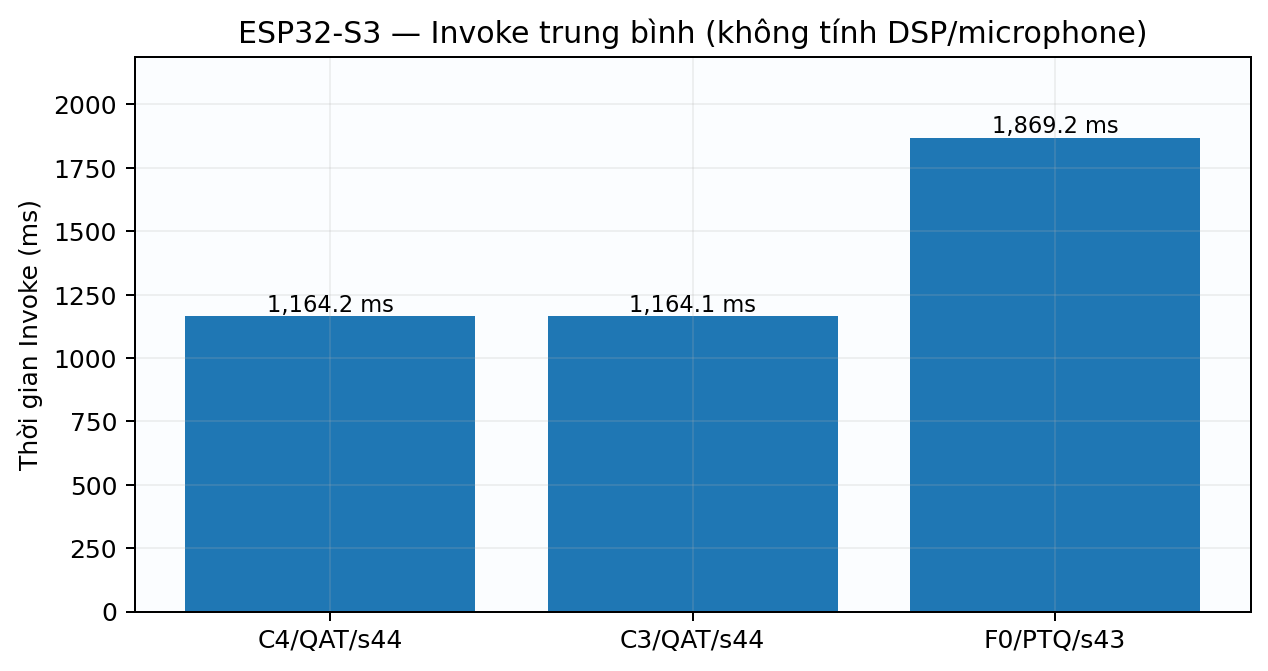

In [3]:
show_image('figures/05_Deployment/01_ESP32_Invoke_Logs.png')
show_log('logs/C4_QAT_ESP32_Static.log', 70)
show_log('logs/Raw_to_Inference_Parity.log', 90)

## 3. CHECK, MONITOR và vitals - Q21, Q22, Q76-Q78

CHECK thực hiện một phiên suy luận rồi đo vitals; MONITOR thực hiện ba lần và majority vote. Vitals không được đưa vào model vì chưa có dataset multimodal đồng bộ. Giá trị 0 là sentinel khi timeout, Dashboard phải hiểu là không có dữ liệu.

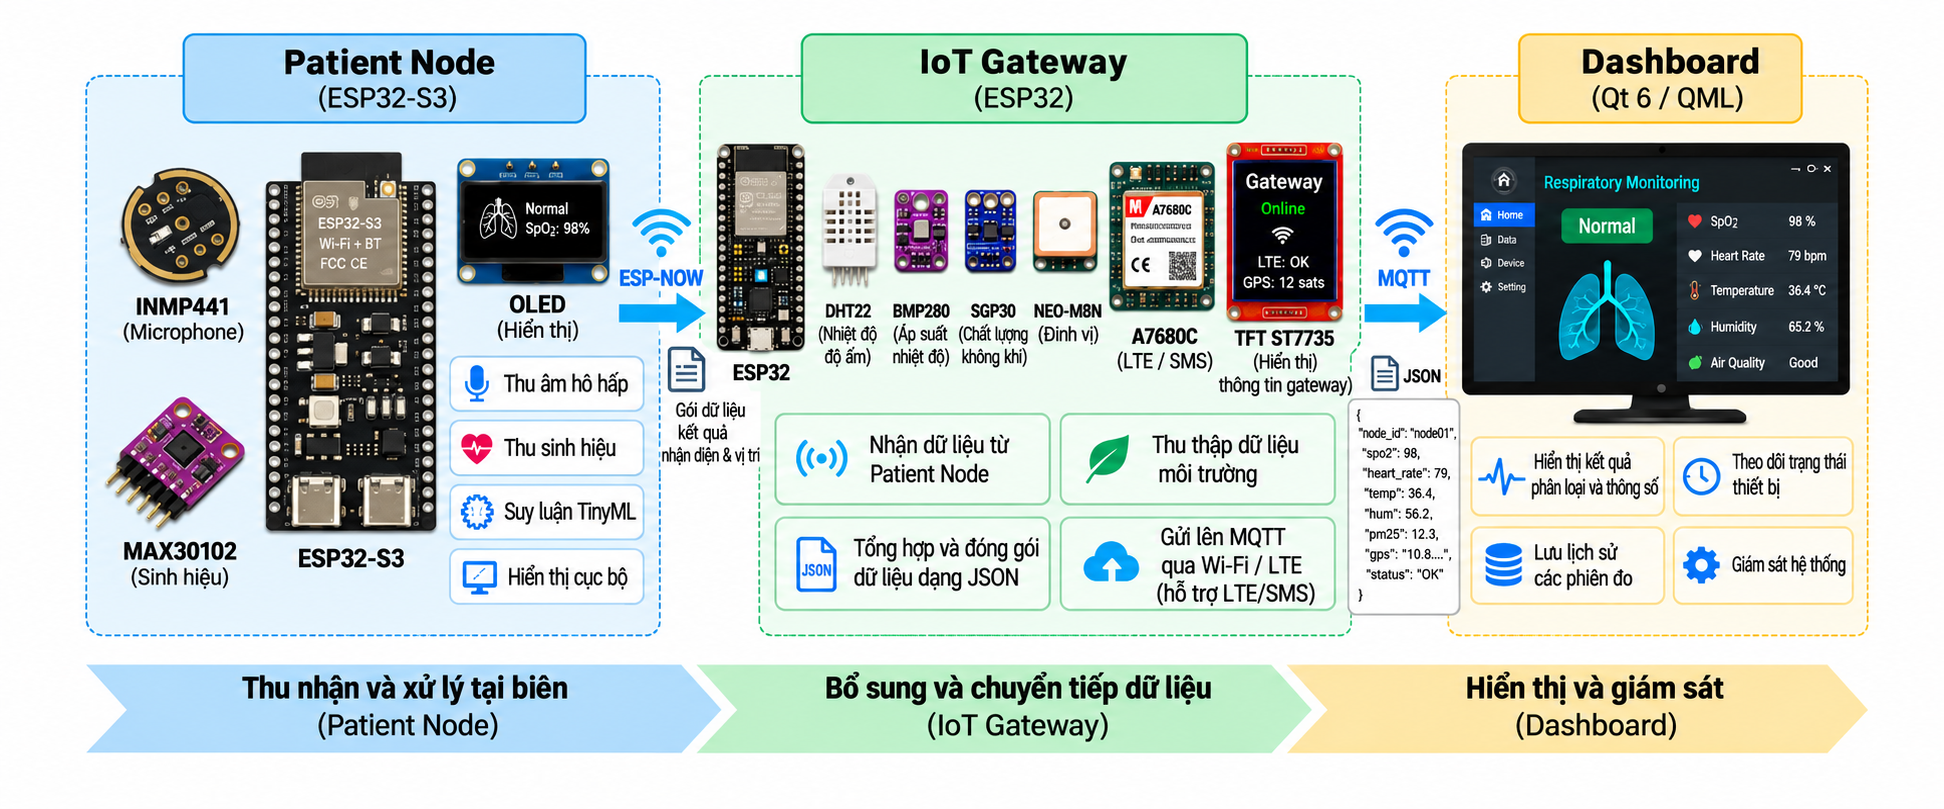

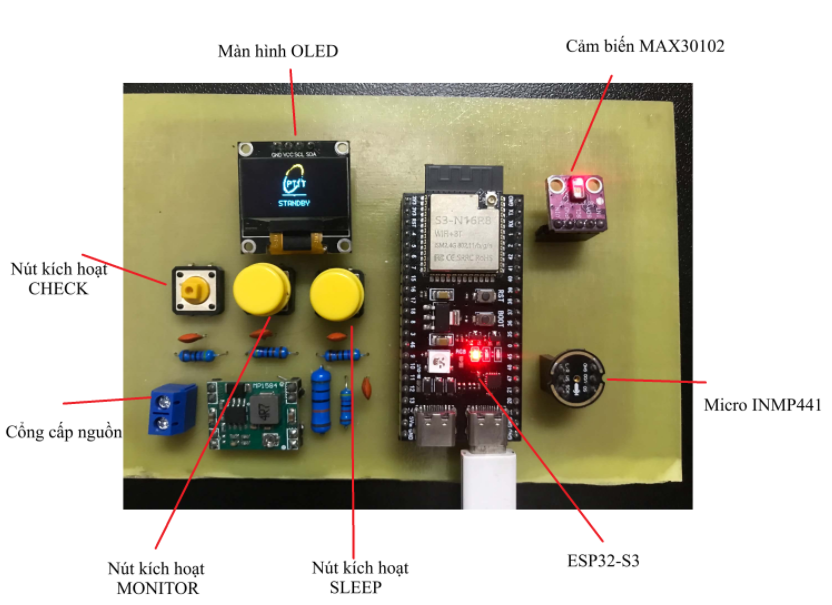

In [4]:
show_image('figures/06_System/01_System_Workflow.png')
show_image('figures/06_System/02_Patient_Node.png', width=850)

## 4. ESP-NOW, AES-GCM và Gateway - Q29-Q39, Q74-Q75

ESP-NOW vận chuyển gói nhỏ; AES-GCM bảo mật nội dung và tag; sequence/session hỗ trợ chống replay; ACK/retry xử lý delivery ở tầng ứng dụng. CRC không thay thế xác thực mật mã.

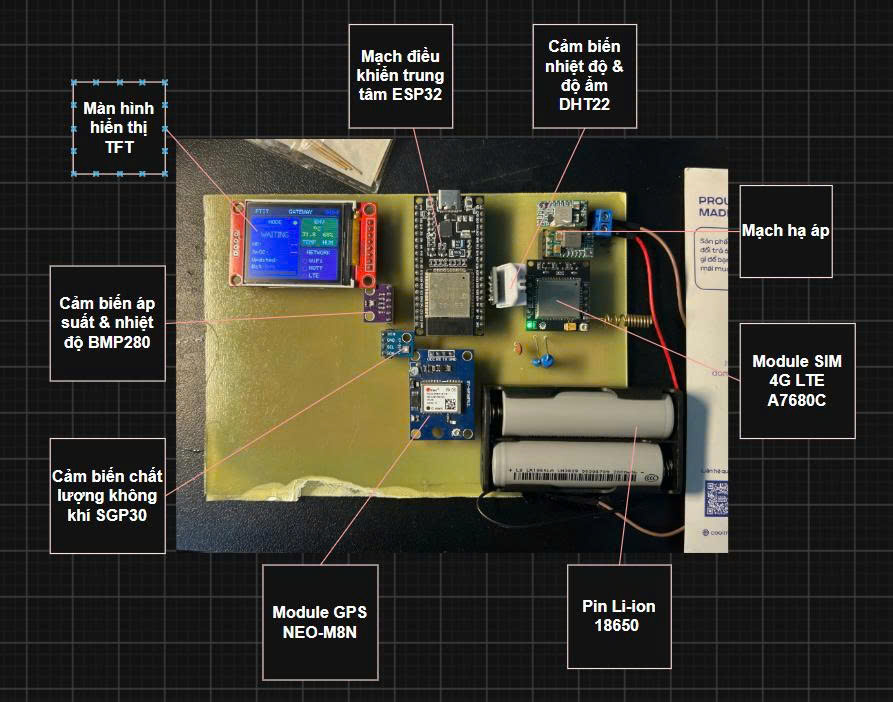

In [5]:
show_image('figures/06_System/03_Gateway.jpg', width=850)
show_log('logs/Gateway_Test_Result.txt', 120)

## 5. MQTT, Dashboard và giới hạn mất kết nối - Q44-Q56, Q79

Gateway chuyển event thành JSON và publish cho Dashboard. Bằng chứng Wi-Fi/LTE hiện có là code + native/mock test; chưa được gọi là hardware failover nếu chưa có log LTE thật. Hệ thống cũng chưa phải persistent store-and-forward hoàn chỉnh.

{'schema_version': 1,
 'message_type': 'complete_packet',
 'record_id': '47575431-00000001-00000002',
 'synthetic': False,
 'has_patient_event': True,
 'source': {'device_id': 123, 'sequence': 19, 'received_uptime_ms': 9000},
 'gate': {'gateway_id': 1196905521,
  'timestamp': 10000,
  'time_basis': 'uptime_ms',
  'operating_mode': 0,
  'uplink_type': 1,
  'sensor_valid_mask': 0,
  'temperature': None,
  'humidity': None,
  'pressure': None,
  'tvoc': None,
  'eco2': None,
  'wifi_connected': True,
  'wifi_rssi_dbm': -55,
  'lte_registered': False,
  'lte_rssi_dbm': None,
  'mqtt_connected': True,
  'latitude': None,
  'longitude': None,
  'gps_timestamp': None,
  'battery_gate': None},
 'patient_event': {'session_id': 42,
  'timestamp': None,
  'time_basis': 'unsynced',
  'event_type': 0,
  'classification': 0,
  'model_score': 0.9,
  'audio_quality': 0,
  'vitals_valid': True,
  'heart_rate': 72,
  'spo2': None,
  'battery_node': None},
 'transport': 'wifi',
 'event_id': '0000007b-000

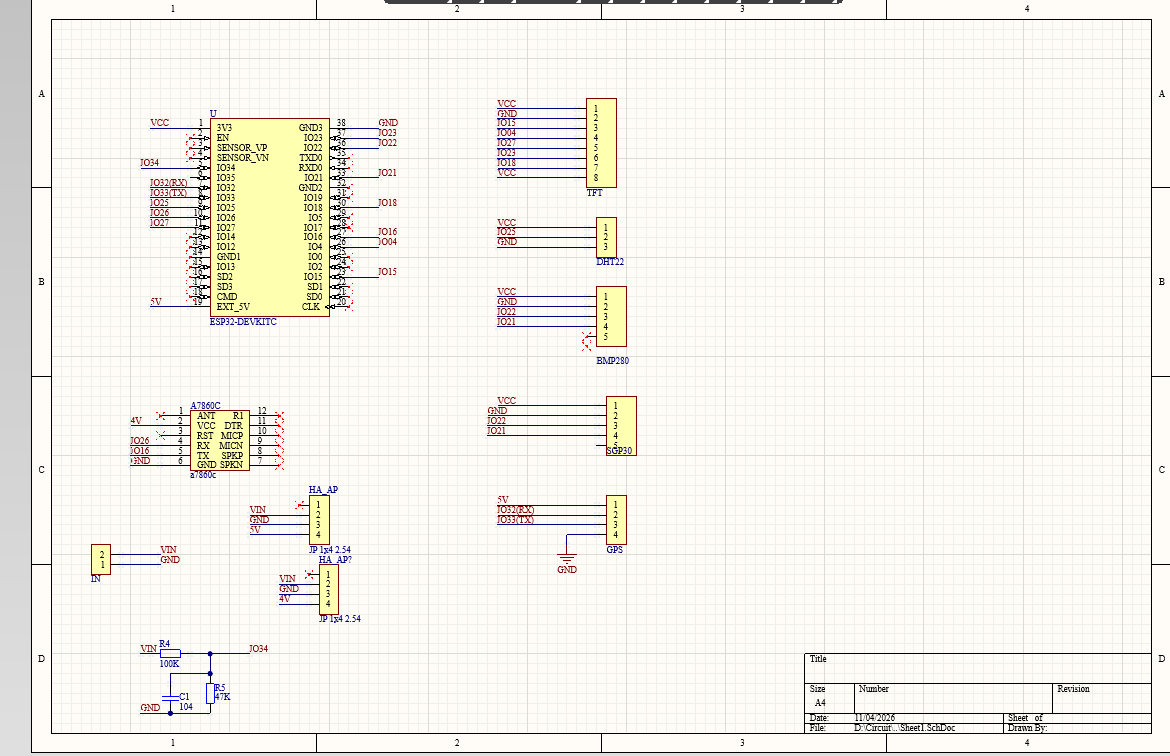

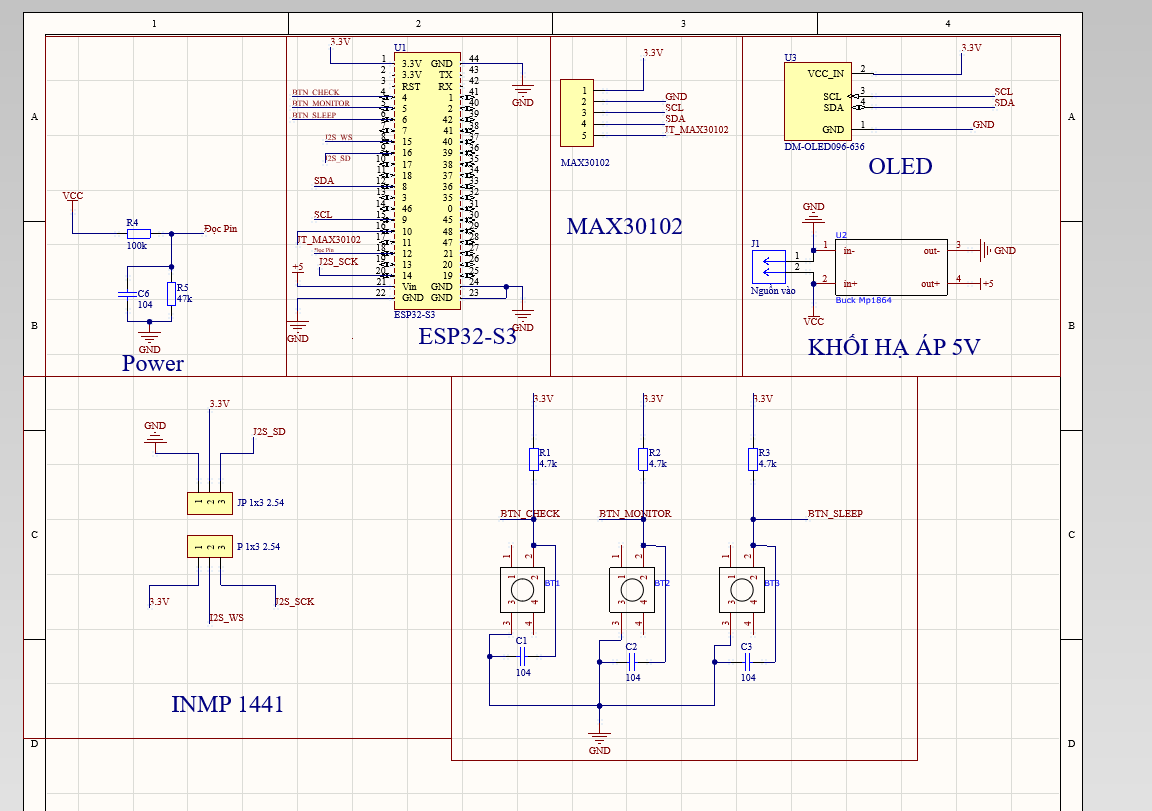

In [6]:
json_path = EVIDENCE / 'data/Dashboard_MQTT_Example.json'
payload = json.loads(json_path.read_text(encoding='utf-8'))
display(payload)
show_image('figures/06_System/04_Patient_Node_PCB.png', width=900)
show_image('figures/06_System/05_Gateway_PCB.png', width=900)

## 6. Câu chốt khi trình bày

> Hệ thống tách trigger, kiểm tra chất lượng và phân loại; suy luận tại Node; truyền kết quả nhỏ qua ESP-NOW có xác thực; Gateway ghép dữ liệu và đưa lên MQTT. Những phần chưa có log hardware thật được nêu là giới hạn, không biến thành kết quả đã kiểm chứng.

Đáp án chi tiết: [Q71](../01_Committee_QnA/Answers/Q71.md), [Q73](../01_Committee_QnA/Answers/Q73.md), [Q74](../01_Committee_QnA/Answers/Q74.md), [Q79](../01_Committee_QnA/Answers/Q79.md), [Q80](../01_Committee_QnA/Answers/Q80.md).